In [1]:
# test reader loading and reading the files

from czmeltbench.data.reader import CZDataReader

reader = CZDataReader(
    "../data/raw"
)

case_ids = reader.list_cases()

print("Accepted DOE cases:", len(case_ids))

pos, mu, y = reader.load_arrays("sobol_000")

print("Coordinates:", pos.shape)
print("Parameters:", mu.shape)
print("Fields:", y.shape)

Accepted DOE cases: 254
Coordinates: (8181, 2)
Parameters: (3,)
Fields: (8181, 5)


In [2]:
# test for reference coordinates
# 
import numpy as np 

reference_pos = reader.load_reference_positions("base")

print("Referece mesh:", reference_pos.shape)

print(
    "Same node ordering:",
    np.array_equal(pos, reference_pos)
)

Referece mesh: (8181, 2)
Same node ordering: True


# Test mesh reconstruction

In [3]:
from czmeltbench.geometry.mesh import (
    LogicalMesh,
    build_logical_mesh
)

pos, mu, y = reader.load_arrays("sobol_000")

mesh = build_logical_mesh(pos)

print("Mesh shape:", mesh.shape)
print("Radial nodes:", mesh.nr)
print("Axial levels:", mesh.nz)
print("Total nodes:", mesh.num_nodes)

Mesh shape: (81, 101)
Radial nodes: 101
Axial levels: 81
Total nodes: 8181


In [4]:
reconstructed_pos = mesh.original_coordinates()

print(
    "coordinates preserved:", np.array_equal(pos, reconstructed_pos)
)

coordinates preserved: True


In [5]:
import numpy as np
from czmeltbench.geometry.boundaries import (
    identify_boundaries,
    boundary_features,
    distance_features
)



In [6]:
# laod adnd classify nodes

pos, mu, y = reader.load_arrays("sobol_000")

masks = identify_boundaries(pos)

for name, mask in masks.items():
    print(f"{name:12s}: {mask.sum()}")

axis        : 81
bottom      : 101
wall        : 81
crystal     : 57
lid         : 45
interior    : 7821


In [7]:
# validate unique boundary counts
boundary_union = np.logical_or.reduce([
    masks[name] for name in (
        "axis", "bottom", "wall", "crystal", "lid"
    )
])

assert boundary_union.sum() == 360
assert masks["interior"].sum() == 7821
assert np.all(~boundary_union == masks["interior"])

print("Boundary classification validated")

Boundary classification validated


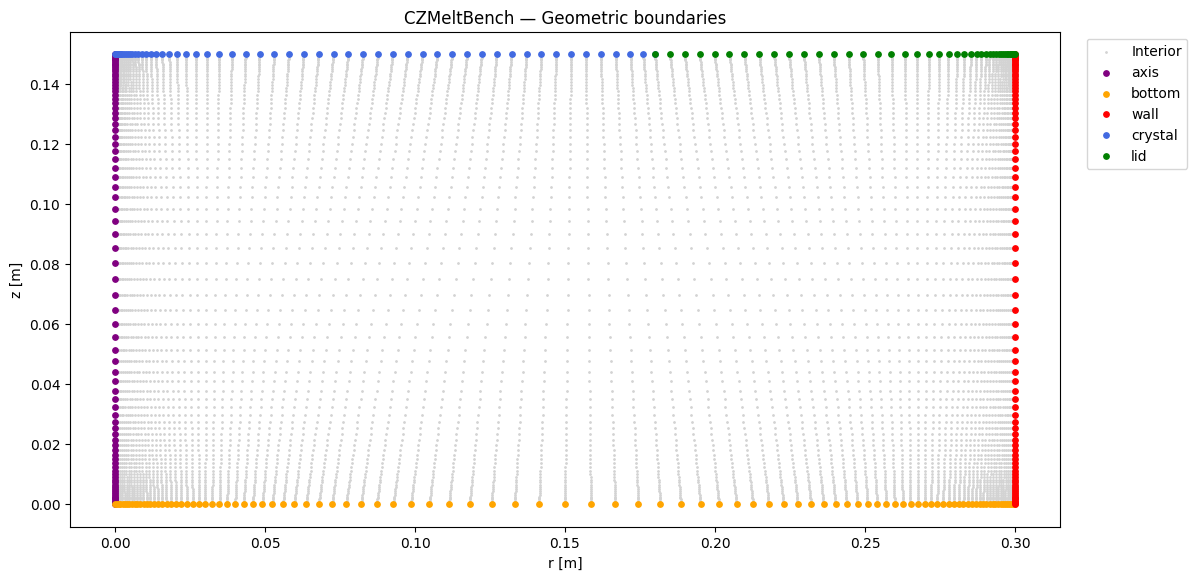

In [8]:
# Visualize boundary features

import matplotlib.pyplot as plt

names = ["axis", "bottom", "wall", "crystal", "lid"]

colors = [
    "purple", "orange", "red",
    "royalblue", "green"
]

fig, ax = plt.subplots(figsize=(12, 6))

ax.scatter(
    pos[masks["interior"], 0],
    pos[masks["interior"], 1],
    s=1,
    color="lightgray",
    label="Interior",
)

for name, color in zip(names, colors):

    mask = masks[name]

    ax.scatter(
        pos[mask, 0],
        pos[mask, 1],
        s=15,
        color=color,
        label=name,
    )

ax.set_xlabel("r [m]")
ax.set_ylabel("z [m]")
ax.set_title("CZMeltBench — Geometric boundaries")
ax.set_aspect("equal")
ax.legend(bbox_to_anchor=(1.02, 1))

plt.tight_layout()
plt.show()

## TEst Bounndary condition implementationn

In [9]:
# import new module of BC

from czmeltbench.physics.boundary_conditions import (
    BoundaryConditions,
    compute_boundary_conditions,
    rpm_to_rad_per_sec,
)

from czmeltbench.constants import FIELD_COLUMNS

In [11]:
# load sim and calculate BCs

pos, mu, y = reader.load_arrays("sobol_000")

bc = compute_boundary_conditions(pos=pos, mu=mu)

print("Values shape:", bc.values.shape)
print("Mask shape:", bc.mask.shape)
print("Number of nodes:", bc.num_nodes)



Values shape: (8181, 5)
Mask shape: (8181, 5)
Number of nodes: 8181


In [12]:
for i, field in enumerate(FIELD_COLUMNS):
    print(
        f"{field:10s}: "
        f"{bc.mask[:, 1].sum()} nodes"
    )

u_r       : 281 nodes
u_z       : 281 nodes
u_swirl   : 281 nodes
p         : 281 nodes
T         : 281 nodes


In [ ]:
# boundary agremnet validation
import numpy as np
import pandas as pd 

def 